In [62]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import statsmodels.api as sm
from xgboost import XGBRegressor
from scipy import stats
import seaborn as sns
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, ccf
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [3]:
df = pd.read_csv('energy_dataset.csv')
df['time'] = pd.to_datetime(df['time'], utc=True)
df = df.set_index('time').sort_index()
df.head()

,generation biomass,generation fossil brown coal/lignite,generation fossil coal-derived gas,generation fossil gas,generation fossil hard coal,generation fossil oil,generation fossil oil shale,generation fossil peat,generation geothermal,generation hydro pumped storage aggregated,...,generation waste,generation wind offshore,generation wind onshore,forecast solar day ahead,forecast wind offshore eday ahead,forecast wind onshore day ahead,total load forecast,total load actual,price day ahead,price actual
time,,,,,,,,,,,,,,,,,,,,,
2014-12-31 23:00:00+00:00,447.0,329.0,0.0,4844.0,4821.0,162.0,0.0,0.0,0.0,NaN,...,196.0,0.0,6378.0,17.0,NaN,6436.0,26118.0,25385.0,50.10,65.41
2015-01-01 00:00:00+00:00,449.0,328.0,0.0,5196.0,4755.0,158.0,0.0,0.0,0.0,NaN,...,195.0,0.0,5890.0,16.0,NaN,5856.0,24934.0,24382.0,48.10,64.92
2015-01-01 01:00:00+00:00,448.0,323.0,0.0,4857.0,4581.0,157.0,0.0,0.0,0.0,NaN,...,196.0,0.0,5461.0,8.0,NaN,5454.0,23515.0,22734.0,47.33,64.48
2015-01-01 02:00:00+00:00,438.0,254.0,0.0,4314.0,4131.0,160.0,0.0,0.0,0.0,NaN,...,191.0,0.0,5238.0,2.0,NaN,5151.0,22642.0,21286.0,42.27,59.32
2015-01-01 03:00:00+00:00,428.0,187.0,0.0,4130.0,3840.0,156.0,0.0,0.0,0.0,NaN,...,189.0,0.0,4935.0,9.0,NaN,4861.0,21785.0,20264.0,38.41,56.04


In [4]:
expected_timeline = pd.date_range(df.index.min(), df.index.max(), freq='h')
assert df.index.equals(expected_timeline), 'Check time first'

In [5]:
supply = df.filter(regex=r'^generation')
# supply = supply.drop(columns='generation hydro pumped storage consumption')
active = (supply.notna() & supply.ne(0)).any()
supply = supply.loc[:, active]
supply.columns = supply.columns.str.removeprefix('generation ')
supply.describe().round(2)

,biomass,fossil brown coal/lignite,fossil gas,fossil hard coal,fossil oil,hydro pumped storage consumption,hydro run-of-river and poundage,hydro water reservoir,nuclear,other,other renewable,solar,waste,wind onshore
count,35045.00,35046.00,35046.00,35046.00,35045.00,35045.00,35045.00,35046.00,35047.00,35046.00,35046.00,35046.00,35045.00,35046.00
mean,383.51,448.06,5622.74,4256.07,298.32,475.58,972.12,2605.11,6263.91,60.23,85.64,1432.67,269.45,5464.48
std,85.35,354.57,2201.83,1961.60,52.52,792.41,400.78,1835.20,839.67,20.24,14.08,1680.12,50.20,3213.69
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,333.00,0.00,4126.00,2527.00,263.00,0.00,637.00,1077.25,5760.00,53.00,73.00,71.00,240.00,2933.00
50%,367.00,509.00,4969.00,4474.00,300.00,68.00,906.00,2164.00,6566.00,57.00,88.00,616.00,279.00,4849.00
75%,433.00,757.00,6429.00,5838.75,330.00,616.00,1250.00,3757.00,7025.00,80.00,97.00,2578.00,310.00,7398.00
max,592.00,999.00,20034.00,8359.00,449.00,4523.00,2000.00,9728.00,7117.00,106.00,119.00,5792.00,357.00,17436.00


In [6]:
supply_audit = pd.DataFrame({
    "recorded values": supply.count(),
    "missing values": supply.isna().sum(),
    "zero values": supply.eq(0).sum(),
    "duplicated rows": supply.index.duplicated(keep='first').sum()
})
print(f"Total rows: {len(supply)}")
display(supply_audit)

Total rows: 35064


,recorded values,missing values,zero values,duplicated rows
biomass,35045,19,4,0
fossil brown coal/lignite,35046,18,10517,0
fossil gas,35046,18,1,0
fossil hard coal,35046,18,3,0
fossil oil,35045,19,3,0
hydro pumped storage consumption,35045,19,12607,0
hydro run-of-river and poundage,35045,19,3,0
hydro water reservoir,35046,18,3,0
nuclear,35047,17,3,0
other,35046,18,4,0


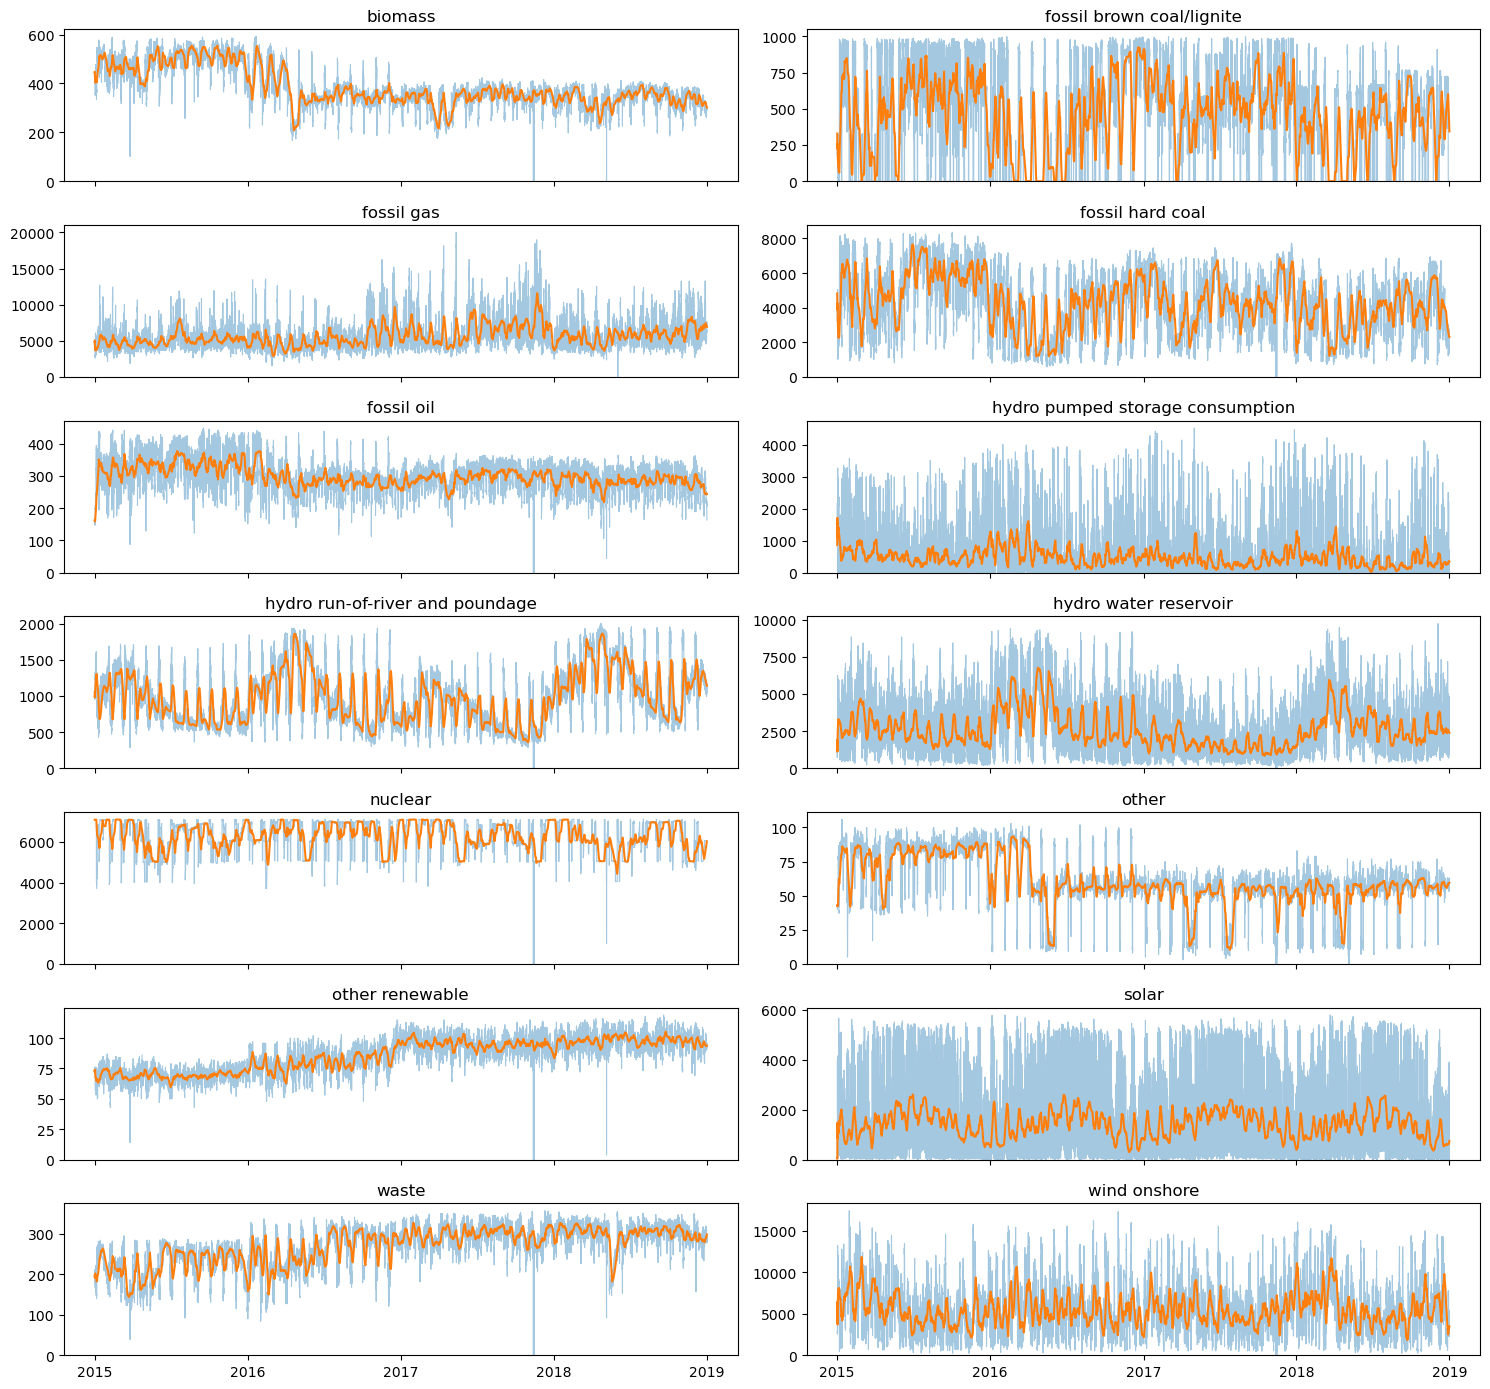

In [7]:
# Whole 5 yrs plot
fig, axes = plt.subplots(7, 2, figsize=(15,14), sharex=True)
for ax, column in zip(axes.flat, supply.columns):
    ax.plot(supply.index, supply[column], linewidth=0.8, alpha=0.4, color='tab:blue')
    ax.plot(supply.index, supply[column].rolling("7D").mean(), color="tab:orange")
    ax.set_ylim(bottom=0)
    ax.set_title(column)

axes[-1, 0].xaxis.set_major_locator(mdates.YearLocator())
fig.tight_layout()
plt.show()

(0.0, 2084.7922020609317)

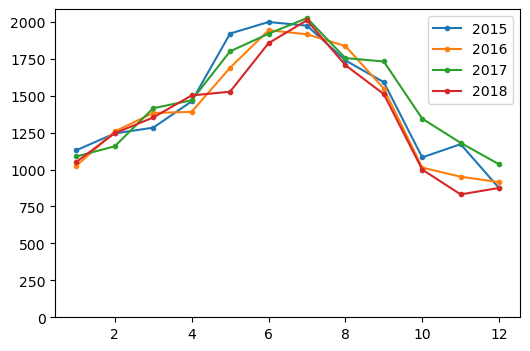

In [8]:
# find patterns in different months
supply = supply.tz_convert("Europe/Madrid")
daily = supply.resample('D').mean()
monthly = supply.resample('MS').mean()

solar_profile = monthly['solar'].groupby([monthly.index.year, monthly.index.month]).mean().unstack(level=0)

fig, ax = plt.subplots(figsize=(6,4))
for year in solar_profile.columns:
    ax.plot(solar_profile.index, solar_profile[year], '.-', label=str(year))
ax.legend()
ax.set_ylim(bottom=0)


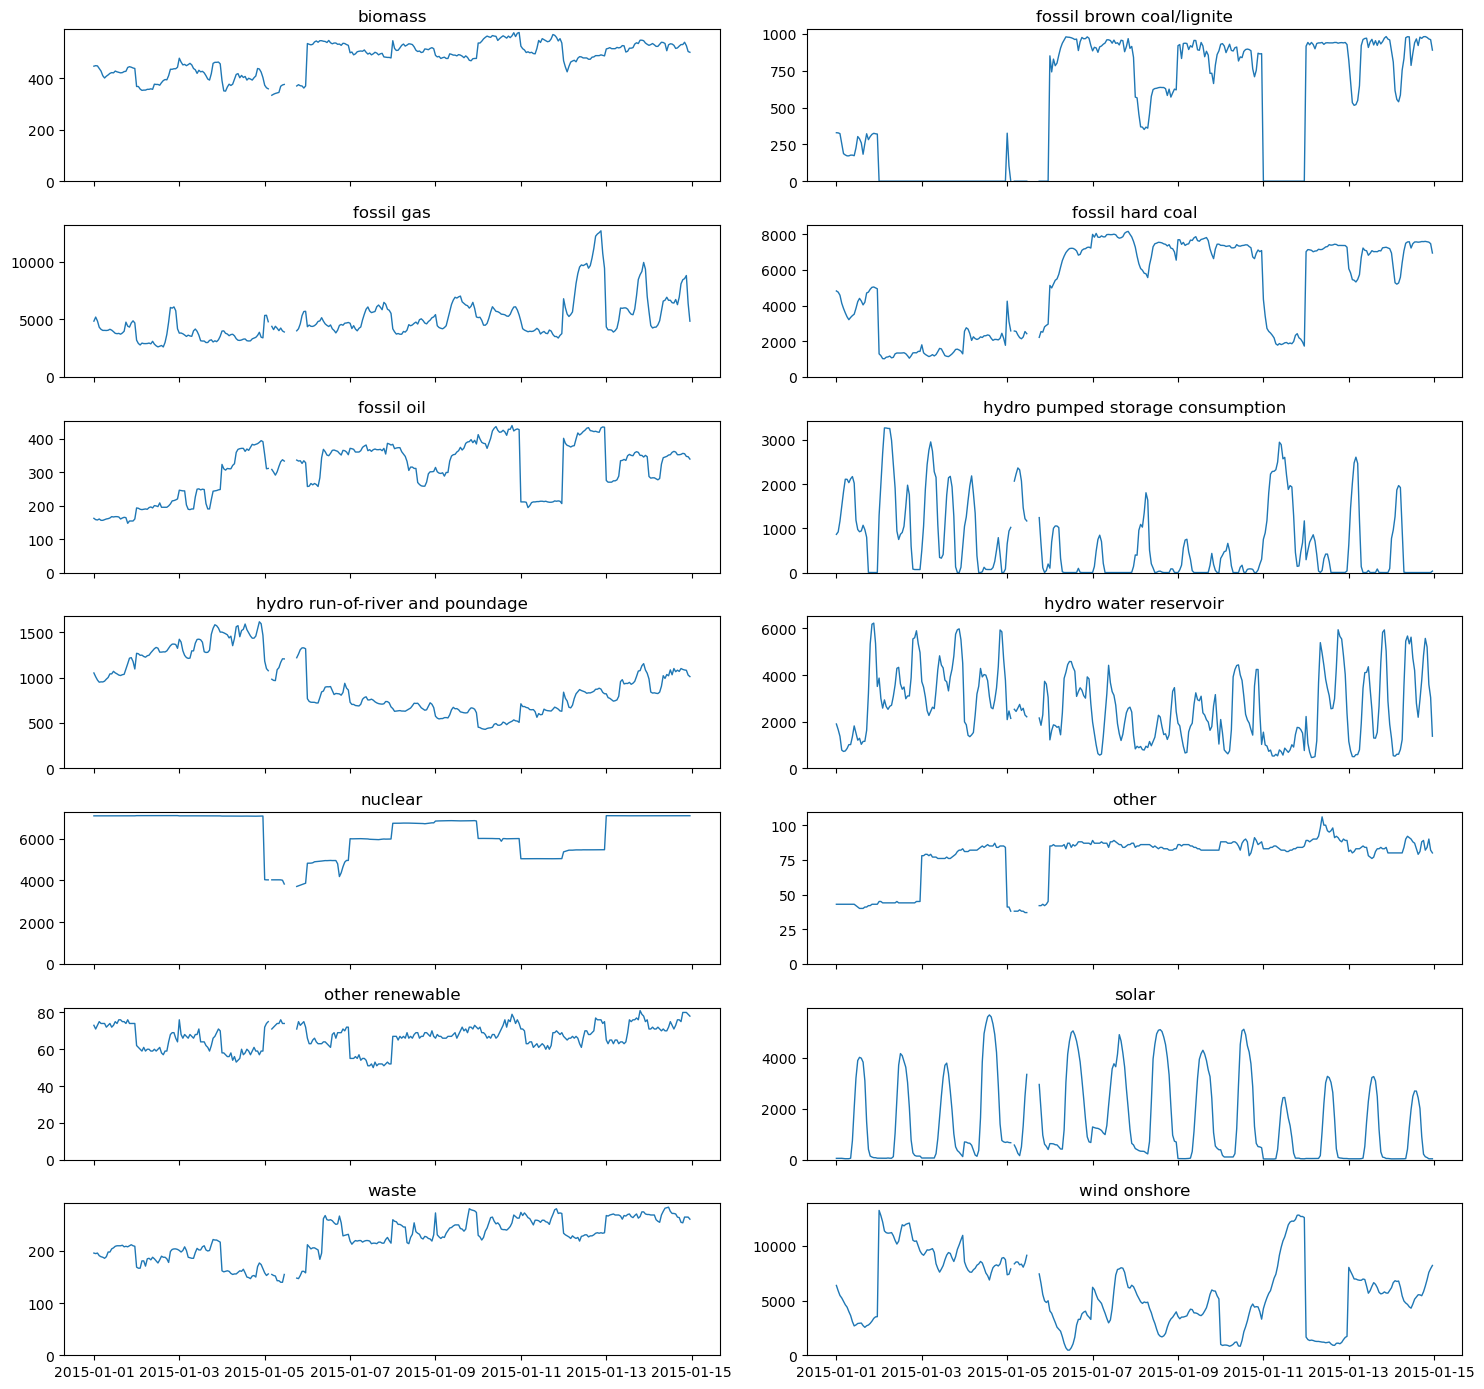

In [9]:
# zoom in first two weeks
df_temp = supply.iloc[:14*24]
fig, axes = plt.subplots(7, 2, figsize=(15,14), sharex=True)
for ax, column in zip(axes.flat, df_temp.columns):
    ax.plot(df_temp.index, df_temp[column], linewidth=1, color='tab:blue')
    ax.set_ylim(bottom=0)
    ax.set_title(column)

# axes[-1, 0].xaxis.set_major_locator(mdates.DateLocator())
fig.tight_layout()
plt.show()

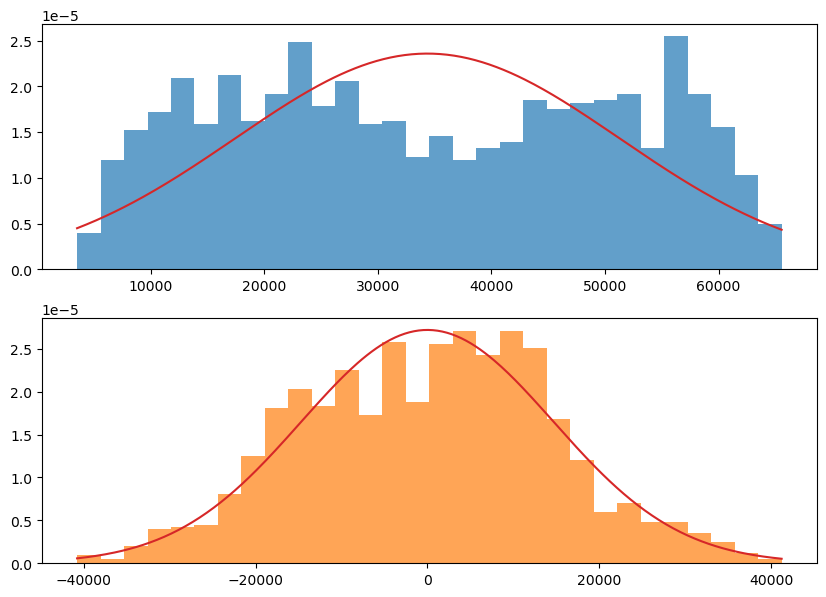

In [10]:
daily_solar = supply['solar'].resample('D').sum()
monthly_solar_mean = daily_solar.groupby(daily_solar.index.month).transform('mean')
adjusted_daily_solar = daily_solar - monthly_solar_mean

fig, axes = plt.subplots(2, 1, figsize=(10, 7))
values = daily_solar.dropna()
axes[0].hist(values, bins=30, density=True, alpha=0.7)
x = np.linspace(values.min(), values.max(), 300)
axes[0].plot(x, stats.norm.pdf(x, values.mean(), values.std()), color='tab:red')

values = adjusted_daily_solar.dropna()
axes[1].hist(values, bins=30, density=True, alpha=0.7, color='tab:orange')
x = np.linspace(values.min(), values.max(), 300)
axes[1].plot(x, stats.norm.pdf(x, values.mean(), values.std()), color='tab:red')


,n,skewness,kurtosis
Original,1461.0,0.039571,-1.267427
Monthly adjusted,1461.0,0.001856,-0.340081
Yeo-Johnson adjusted,1461.0,0.067606,-0.325721


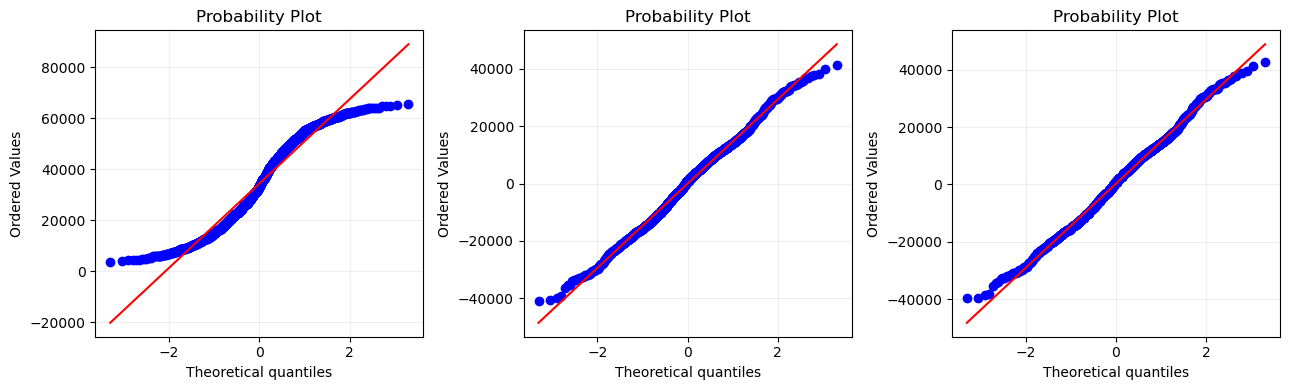

In [11]:
valid_adjusted = adjusted_daily_solar.dropna()
transformed_values, fitted_lambda = stats.yeojohnson(valid_adjusted.to_numpy())
transformed = pd.Series(transformed_values, index=valid_adjusted.index, name='Yeo_Johnson')
transformed

def distribution_summary(series):
    values = series.dropna()
    return pd.Series({
        'n': len(values),
        'skewness': values.skew(),
        'kurtosis': values.kurtosis()
    })

comparison = pd.DataFrame({
    'Original': distribution_summary(daily_solar),
    'Monthly adjusted': distribution_summary(adjusted_daily_solar),
    'Yeo-Johnson adjusted': distribution_summary(transformed)
}).T
display(comparison)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, series, label in zip(axes, [daily_solar, adjusted_daily_solar, transformed], ['Original', 'Monthly adjusted', 'Yeo-Johnson adjusted']):
    stats.probplot(series.dropna(), dist='norm', plot=ax)
    ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

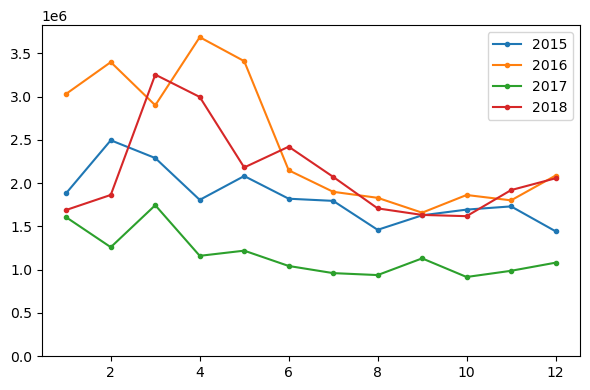

In [12]:
daily_water = supply['hydro water reservoir'].resample('D').sum()
monthly_water = supply['hydro water reservoir'].resample('MS').sum()
water_profile = monthly_water.groupby([monthly_water.index.month, monthly_water.index.year]).mean().unstack()

fig, ax = plt.subplots(figsize=(6, 4))
for col in water_profile.columns:
    values = water_profile[col]
    ax.plot(values.index, values, '.-', label=str(col))
ax.set_ylim(bottom=0)
ax.legend()
fig.tight_layout()
plt.show()

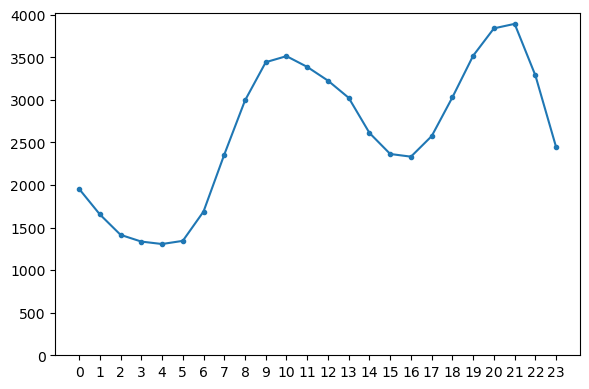

In [13]:
hourly_water = supply['hydro water reservoir']

fig, ax = plt.subplots(figsize=(6, 4))
values = hourly_water.groupby([hourly_water.index.hour]).mean()
ax.plot(values.index, values, '.-')
ax.set_ylim(bottom=0)
ax.set_xticks(range(24))
fig.tight_layout()
plt.show()

Second part: ML prediction

In [14]:
X = supply[['biomass', 'hydro water reservoir', 'solar', 'nuclear', 'wind onshore', 'fossil hard coal', 'hydro pumped storage consumption']]
Y = supply['fossil gas']
X = X.fillna(X.mean())
Y = Y.fillna(Y.mean())
Z = pd.concat([X, Y], axis=1)

<Axes: >

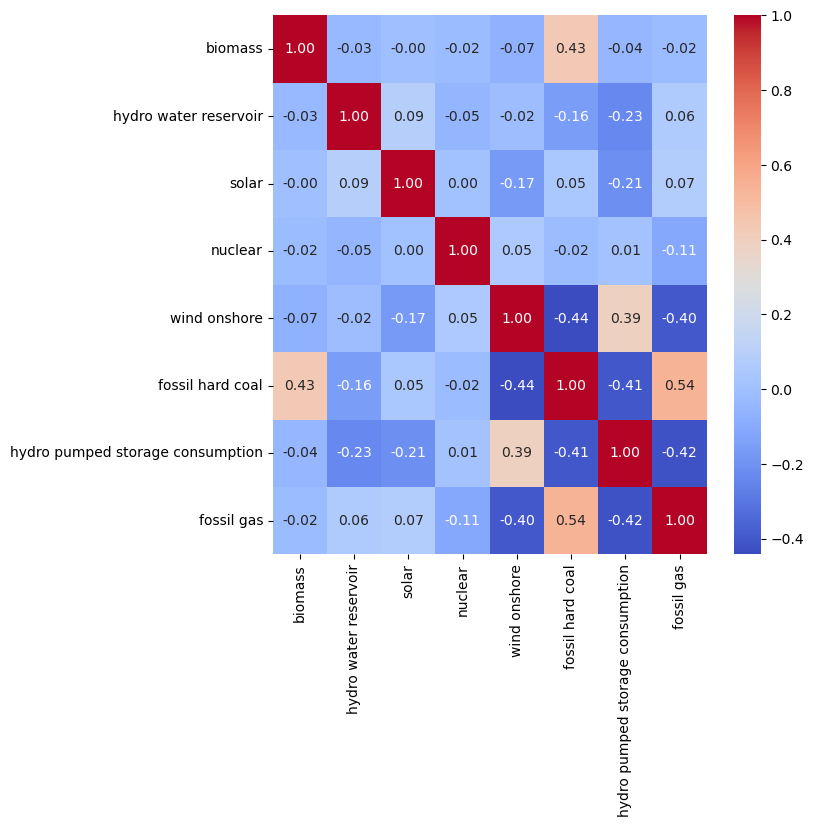

In [15]:
correlations = Z.corr(method='pearson')
fig = plt.figure(figsize=(7, 7))
sns.heatmap(
    correlations, cmap='coolwarm',
    annot=True, fmt='.2f'
    )

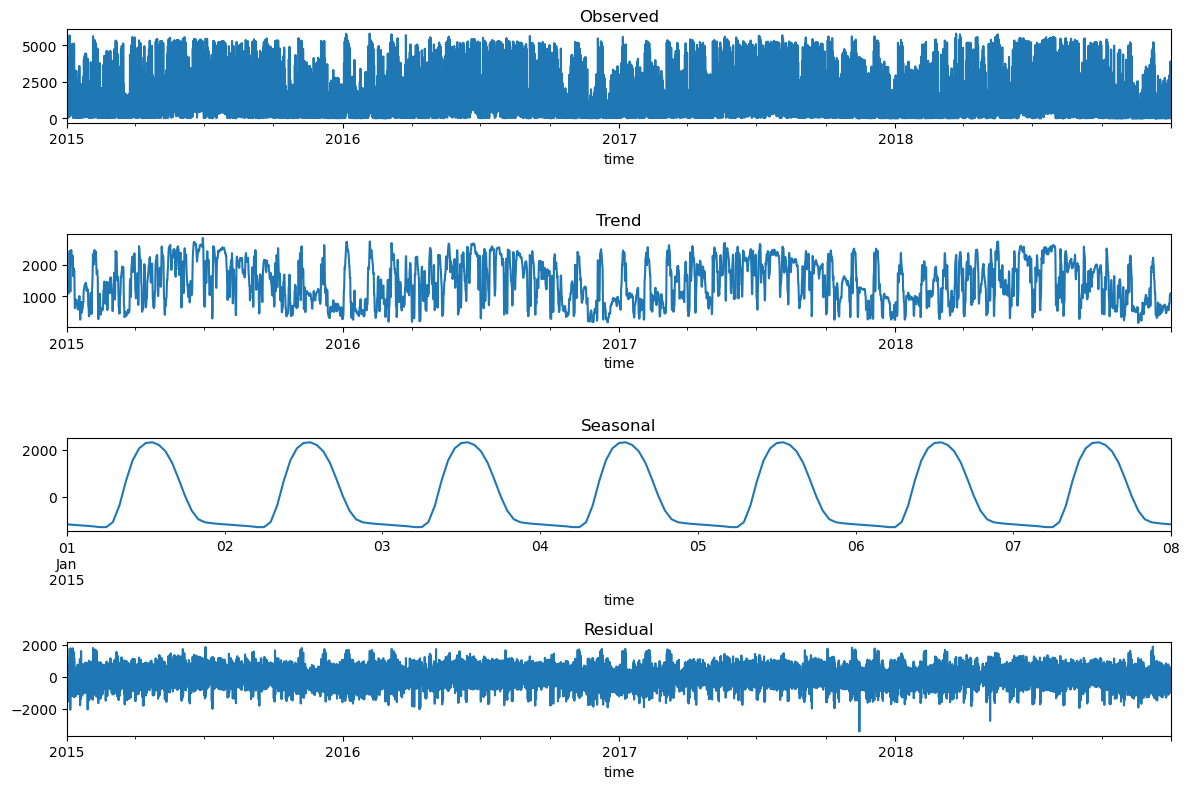

In [16]:
solar_res = sm.tsa.seasonal_decompose(X['solar'], model='additive')
fig, (ax1, ax2, ax3, ax4) = plt.subplots(4, 1, figsize=(12, 8))
solar_res.observed.plot(ax=ax1, title='Observed')
solar_res.trend.plot(ax=ax2, title='Trend')
solar_res.seasonal.plot(ax=ax3, title='Seasonal')
start = solar_res.seasonal.index.min()
ax3.set_xlim(start, start+pd.DateOffset(weeks=1))
solar_res.resid.plot(ax=ax4, title='Residual')
plt.tight_layout()
plt.show()

In [17]:
adf_test = adfuller(X['solar'], regression='c')
print(f'ADF Statistic: {adf_test[0]}\np-value: {adf_test[1]}\nLags used: {adf_test[2]}')
for key, value in adf_test[4].items():
    print(f'Critical Value {key}: {value}')

ADF Statistic: -13.911677548047093
p-value: 5.495946655778373e-26
Lags used: 52
Critical Value 1%: -3.43053679213716
Critical Value 5%: -2.8616225575095284
Critical Value 10%: -2.566813942767471


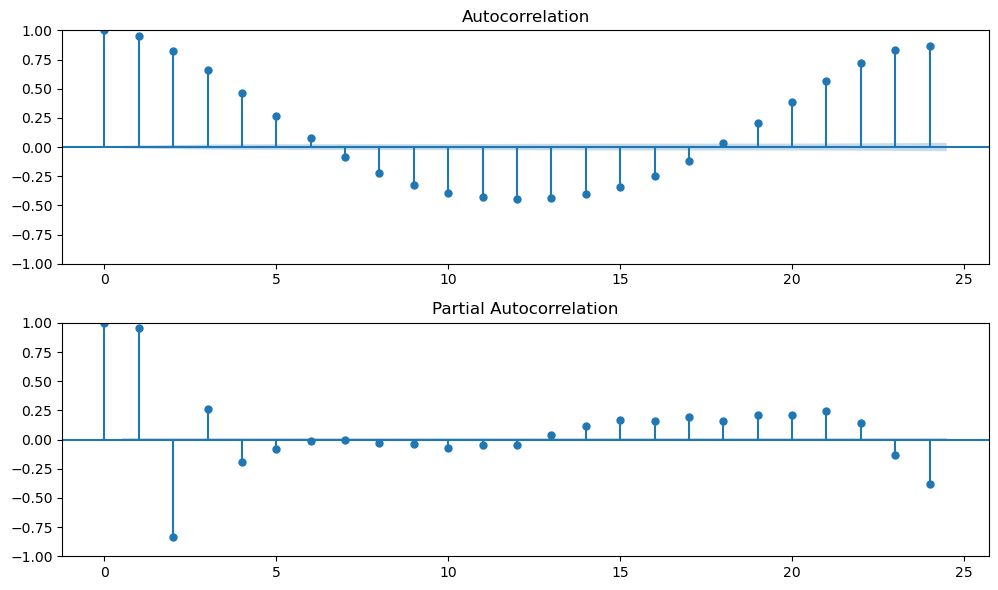

In [113]:
fig, (ax1, ax2) = plt.subplots(nrows=2, figsize=(10, 6))
plot_acf(X['solar'], lags=24, ax=ax1)
plot_pacf(X['solar'], lags=24, ax=ax2)
plt.tight_layout()
plt.show()

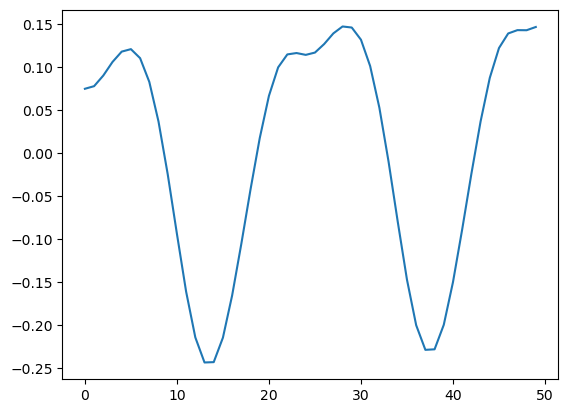

In [18]:
cross_corr = ccf(Y, X['solar'])
plt.plot(cross_corr[0:50])
plt.show()

Feature Engineering

In [19]:
for i in range(len(X)):
    position = X.index[i]
    hour = position.hour
    weekday = position.weekday()
    month = position.month
    X.loc[position, 'hour'] = hour
    X.loc[position, 'weekday'] = weekday
    X.loc[position, 'month'] = month

    if ((hour > 8 and hour < 14) or (hour > 16 and hour < 21)):
        X.loc[position, 'business hour'] = 2
    elif (hour >= 14 and hour <= 16):
        X.loc[position, 'business hour'] = 1
    else:
        X.loc[position, 'business hour'] = 0

X


,biomass,hydro water reservoir,solar,nuclear,wind onshore,fossil hard coal,hydro pumped storage consumption,hour,weekday,month,business hour
time,,,,,,,,,,,
2015-01-01 00:00:00+01:00,447.0,1899.0,49.0,7096.0,6378.0,4821.0,863.0,0.0,3.0,1.0,0.0
2015-01-01 01:00:00+01:00,449.0,1658.0,50.0,7096.0,5890.0,4755.0,920.0,1.0,3.0,1.0,0.0
2015-01-01 02:00:00+01:00,448.0,1371.0,50.0,7099.0,5461.0,4581.0,1164.0,2.0,3.0,1.0,0.0
2015-01-01 03:00:00+01:00,438.0,779.0,50.0,7098.0,5238.0,4131.0,1503.0,3.0,3.0,1.0,0.0
2015-01-01 04:00:00+01:00,428.0,720.0,42.0,7097.0,4935.0,3840.0,1826.0,4.0,3.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...
2018-12-31 19:00:00+01:00,297.0,4836.0,85.0,6073.0,3113.0,2628.0,1.0,19.0,0.0,12.0,2.0
2018-12-31 20:00:00+01:00,296.0,3931.0,33.0,6074.0,3288.0,2566.0,1.0,20.0,0.0,12.0,2.0
2018-12-31 21:00:00+01:00,292.0,2831.0,31.0,6076.0,3503.0,2422.0,50.0,21.0,0.0,12.0,0.0


In [ ]:
train_end = int(len(X) * 0.7)
val_end = int(len(X) * 0.85)
test_end = int(len(X)) 
past_history = 24
future_target = 0

print("Training:", X.index[0], X.index[train_end-1])
print("Validation:", X.index[train_end], X.index[val_end-1])
print("Test:", X.index[val_end], X.index[test_end-1])

Training: 2015-01-01 00:00:00+01:00 2017-10-19 16:00:00+02:00
Validation: 2017-10-19 17:00:00+02:00 2018-05-26 20:00:00+02:00
Test: 2018-05-26 21:00:00+02:00 2018-12-31 23:00:00+01:00


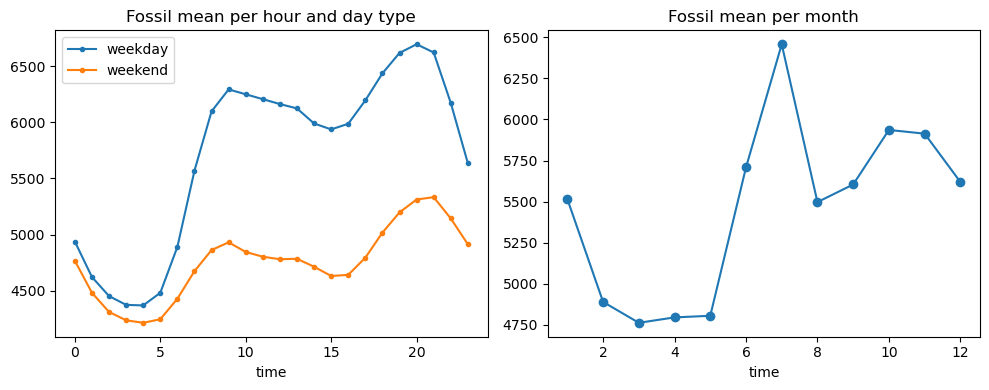

In [37]:
Y_train = Y.iloc[:train_end-1]
local_time = Y_train.index

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
mask = local_time.day_of_week < 5
Y_train.loc[mask].groupby(local_time[mask].hour).mean().plot(ax=axes[0], marker='.', label='weekday')
Y_train.loc[~mask].groupby(local_time[~mask].hour).mean().plot(ax=axes[0], marker='.', label='weekend')
axes[0].legend()
axes[0].set_title('Fossil mean per hour and day type')

Y_train.groupby(local_time.month).mean().plot(ax=axes[1], marker='o')
axes[1].set_title('Fossil mean per month')
plt.tight_layout()
plt.show()


In [42]:
hours_in_day = 24
X['hour_sin'] = np.sin(2 * np.pi * X['hour'] / hours_in_day)
X['hour_cos'] = np.cos(2 * np.pi * X['hour'] / hours_in_day)

months_in_year = 12
X['month_sin'] = np.sin(2 * np.pi * X['month'] / months_in_year)
X['month_cos'] = np.cos(2 * np.pi * X['month'] / months_in_year)

days_in_week = 7
X['weekday_sin'] = np.sin(2 * np.pi * X['weekday'] / days_in_week)
X['weekday_cos'] = np.cos(2 * np.pi * X['weekday'] / days_in_week)
X

,biomass,hydro water reservoir,solar,nuclear,wind onshore,fossil hard coal,hydro pumped storage consumption,hour,weekday,month,business hour,hour_sin,hour_cos,month_sin,month_cos,weekday_sin,weekday_cos
time,,,,,,,,,,,,,,,,,
2015-01-01 00:00:00+01:00,447.0,1899.0,49.0,7096.0,6378.0,4821.0,863.0,0.0,3.0,1.0,0.0,0.000000,1.000000,5.000000e-01,0.866025,0.433884,-0.900969
2015-01-01 01:00:00+01:00,449.0,1658.0,50.0,7096.0,5890.0,4755.0,920.0,1.0,3.0,1.0,0.0,0.258819,0.965926,5.000000e-01,0.866025,0.433884,-0.900969
2015-01-01 02:00:00+01:00,448.0,1371.0,50.0,7099.0,5461.0,4581.0,1164.0,2.0,3.0,1.0,0.0,0.500000,0.866025,5.000000e-01,0.866025,0.433884,-0.900969
2015-01-01 03:00:00+01:00,438.0,779.0,50.0,7098.0,5238.0,4131.0,1503.0,3.0,3.0,1.0,0.0,0.707107,0.707107,5.000000e-01,0.866025,0.433884,-0.900969
2015-01-01 04:00:00+01:00,428.0,720.0,42.0,7097.0,4935.0,3840.0,1826.0,4.0,3.0,1.0,0.0,0.866025,0.500000,5.000000e-01,0.866025,0.433884,-0.900969
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2018-12-31 19:00:00+01:00,297.0,4836.0,85.0,6073.0,3113.0,2628.0,1.0,19.0,0.0,12.0,2.0,-0.965926,0.258819,-2.449294e-16,1.000000,0.000000,1.000000
2018-12-31 20:00:00+01:00,296.0,3931.0,33.0,6074.0,3288.0,2566.0,1.0,20.0,0.0,12.0,2.0,-0.866025,0.500000,-2.449294e-16,1.000000,0.000000,1.000000
2018-12-31 21:00:00+01:00,292.0,2831.0,31.0,6076.0,3503.0,2422.0,50.0,21.0,0.0,12.0,0.0,-0.707107,0.707107,-2.449294e-16,1.000000,0.000000,1.000000


In [43]:
def history_features(frame, lags, windows):
    columns = {}
    for name in frame:
        s = frame[name]
        for lag in lags:
            columns[f'{name}_lag{lag}'] = s.shift(lag)
        past = s.shift(1)
        for window in windows:
            r = past.rolling(window, min_periods=window)
            columns[f'{name}_mean{window}'] = r.mean()
            columns[f'{name}_std{window}'] = r.std()
        columns[f'{name}_change1'] = past - s.shift(2)
        columns[f'{name}_change24'] = past - s.shift(25)
    return pd.DataFrame(columns, index=frame.index)


In [66]:
X_history = history_features(frame=X, lags=[1, 2, 24, 168], windows=[24, 168])
fossil_history = history_features(frame=Y.rename('fossil_gas').to_frame(),
                                  lags=[1, 2, 3, 6, 12, 23, 24, 25, 48, 72, 167, 168, 169], windows=[3, 24, 168])
X_new = pd.concat([X, X_history, fossil_history], axis=1)
X_new

,biomass,hydro water reservoir,solar,nuclear,wind onshore,fossil hard coal,hydro pumped storage consumption,hour,weekday,month,...,fossil_gas_lag168,fossil_gas_lag169,fossil_gas_mean3,fossil_gas_std3,fossil_gas_mean24,fossil_gas_std24,fossil_gas_mean168,fossil_gas_std168,fossil_gas_change1,fossil_gas_change24
time,,,,,,,,,,,,,,,,,,,,,
2015-01-01 00:00:00+01:00,447.0,1899.0,49.0,7096.0,6378.0,4821.0,863.0,0.0,3.0,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2015-01-01 01:00:00+01:00,449.0,1658.0,50.0,7096.0,5890.0,4755.0,920.0,1.0,3.0,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2015-01-01 02:00:00+01:00,448.0,1371.0,50.0,7099.0,5461.0,4581.0,1164.0,2.0,3.0,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,352.0,NaN
2015-01-01 03:00:00+01:00,438.0,779.0,50.0,7098.0,5238.0,4131.0,1503.0,3.0,3.0,1.0,...,NaN,NaN,4965.666667,199.580393,NaN,NaN,NaN,NaN,-339.0,NaN
2015-01-01 04:00:00+01:00,428.0,720.0,42.0,7097.0,4935.0,3840.0,1826.0,4.0,3.0,1.0,...,NaN,NaN,4789.000000,444.914599,NaN,NaN,NaN,NaN,-543.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2018-12-31 19:00:00+01:00,297.0,4836.0,85.0,6073.0,3113.0,2628.0,1.0,19.0,0.0,12.0,...,7967.0,7584.0,6954.666667,609.421310,5972.416667,589.861142,6921.553571,2197.855078,701.0,2151.0
2018-12-31 20:00:00+01:00,296.0,3931.0,33.0,6074.0,3288.0,2566.0,1.0,20.0,0.0,12.0,...,8033.0,7967.0,7373.000000,417.062345,6051.750000,677.385463,6919.571429,2197.056606,41.0,1904.0
2018-12-31 21:00:00+01:00,292.0,2831.0,31.0,6076.0,3503.0,2422.0,50.0,21.0,0.0,12.0,...,7709.0,8033.0,7489.333333,216.037805,6116.666667,714.166383,6914.857143,2195.502344,-393.0,1558.0


In [67]:
X_clean = X_new.sort_index()
Y_clean = Y.reindex(X_clean.index)

keep = X_clean.notna().all(axis=1) & Y_clean.notna()
X_clean = X_clean.loc[keep]
Y_clean = Y_clean.loc[keep]

X_train = X_clean.iloc[:train_end].copy()
Y_train = Y_clean.iloc[:train_end].copy()

X_val = X_clean.iloc[train_end:val_end].copy()
Y_val = Y_clean.iloc[train_end:val_end].copy()

X_test = X_clean.iloc[val_end:].copy()
Y_test = Y_clean.iloc[val_end:].copy()

XGB

In [68]:
XGB_PARAMS = dict(
    objective='reg:squarederror', tree_method='hist', n_estimators=1800,
    learning_rate=.04, max_depth=4, min_child_weight=10,
    subsample=.8, colsample_bytree=.8, reg_lambda=10., reg_alpha=.1,
    eval_metric='rmse', random_state=42, n_jobs=4,
)
EARLY_STOPPING_ROUNDS = 80

n = len(X)
FOLDS = [
    ('early_50', int(n * 0.5), int(n * -.6)),
    ('early_60', int(n *50), train_end),
    ('main', train_end, val_end)
]


In [69]:
tree = XGBRegressor(**XGB_PARAMS, early_stopping_rounds=EARLY_STOPPING_ROUNDS)
tree.fit(X_train, Y_train, eval_set=[(X_val, Y_val)], verbose=200)

[0]	validation_0-rmse:2539.36457
[200]	validation_0-rmse:438.54653
[400]	validation_0-rmse:420.37552
[600]	validation_0-rmse:419.24549
[800]	validation_0-rmse:416.84598
[1000]	validation_0-rmse:416.25042
[1039]	validation_0-rmse:415.91338


,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.8
,device,None
,early_stopping_rounds,80
,enable_categorical,False
,eval_metric,'rmse'


Best boosting round: 960
Best validation RMSE: 415.7864968210617


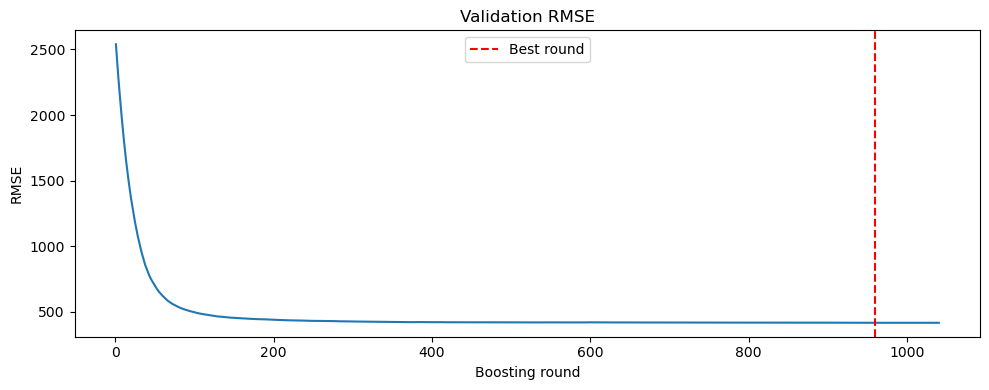

In [70]:
print('Best boosting round:', tree.best_iteration + 1)
print('Best validation RMSE:', tree.best_score)

history = tree.evals_result()
val_rmse = history['validation_0']['rmse']
fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(range(1, len(val_rmse) + 1), val_rmse)
ax.axvline(
    tree.best_iteration + 1,
    color='red', linestyle='--', label='Best round'
)

ax.set(xlabel='Boosting round', ylabel='RMSE', title='Validation RMSE')
ax.legend()
plt.tight_layout()
plt.show()

RMSE: 334.482
MAE: 229.505
R2: 0.973


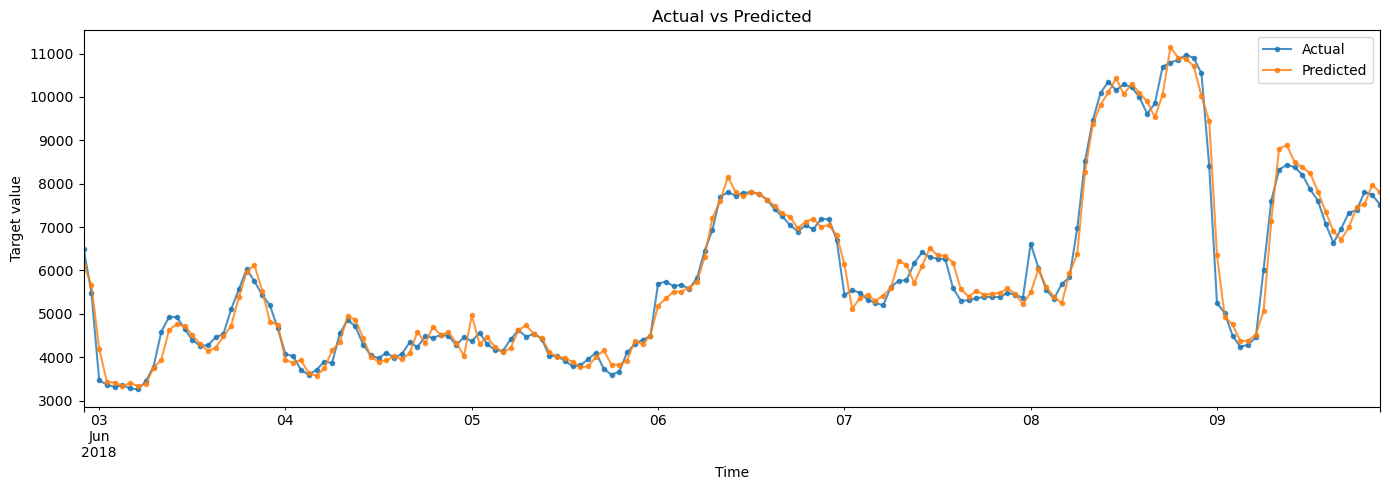

In [71]:
Y_pred = tree.predict(X_test)
rmse = np.sqrt(mean_squared_error(Y_test, Y_pred))
mae = mean_absolute_error(Y_test, Y_pred)
r2 = r2_score(Y_test, Y_pred)

print(f'RMSE: {rmse:.3f}')
print(f'MAE: {mae:.3f}')
print(f'R2: {r2:.3f}')

comparison = pd.DataFrame({
    'Actual': Y_test,
    'Predicted': Y_pred
}, index=Y_test.index)

fig, ax = plt.subplots(figsize=(14, 5))
comparison.iloc[:168].plot(ax=ax, marker='.', alpha=0.8)

ax.set_title('Actual vs Predicted')
ax.set_xlabel('Time')
ax.set_ylabel('Target value')
plt.tight_layout()
plt.show()

Ridge + XGB

In [72]:
linear = make_pipeline(SimpleImputer(strategy='median', add_indicator=True),
                       StandardScaler(), Ridge(alpha=10))
linear.fit(X_train, Y_train)
linear_train = linear.predict(X_train)
linear_valid = linear.predict(X_val)

tree = XGBRegressor(**XGB_PARAMS, early_stopping_rounds=EARLY_STOPPING_ROUNDS)
tree.fit(X_train, Y_train - linear_train, eval_set=[(X_val, Y_val - linear_valid)], verbose=200)



[0]	validation_0-rmse:433.80703
[200]	validation_0-rmse:383.02780
[400]	validation_0-rmse:374.60245
[600]	validation_0-rmse:369.56170
[800]	validation_0-rmse:367.19353
[1000]	validation_0-rmse:365.46191
[1034]	validation_0-rmse:365.28556


,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.8
,device,None
,early_stopping_rounds,80
,enable_categorical,False
,eval_metric,'rmse'


Best boosting round: 955
Best validation RMSE: 365.22692547921855


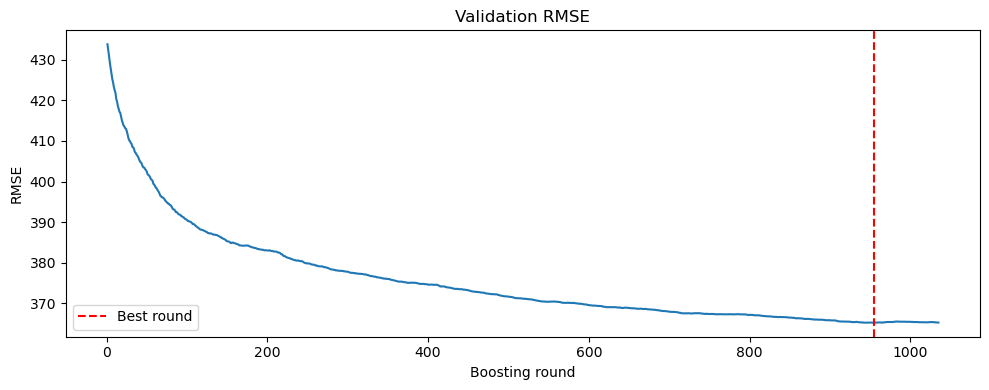

In [73]:
print('Best boosting round:', tree.best_iteration + 1)
print('Best validation RMSE:', tree.best_score)

history = tree.evals_result()
val_rmse = history['validation_0']['rmse']
fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(range(1, len(val_rmse) + 1), val_rmse)
ax.axvline(
    tree.best_iteration + 1,
    color='red', linestyle='--', label='Best round'
)

ax.set(xlabel='Boosting round', ylabel='RMSE', title='Validation RMSE')
ax.legend()
plt.tight_layout()
plt.show()

RMSE: 314.986
MAE: 216.844
R2: 0.976


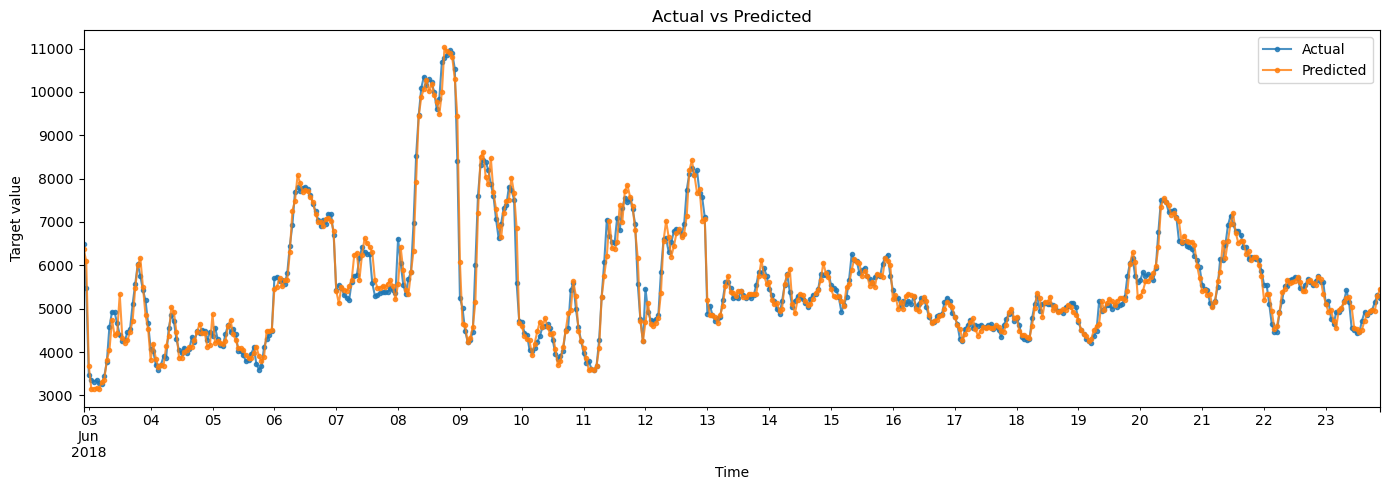

In [76]:
Y_pred = tree.predict(X_test) + linear.predict(X_test)
rmse = np.sqrt(mean_squared_error(Y_test, Y_pred))
mae = mean_absolute_error(Y_test, Y_pred)
r2 = r2_score(Y_test, Y_pred)

print(f'RMSE: {rmse:.3f}')
print(f'MAE: {mae:.3f}')
print(f'R2: {r2:.3f}')

comparison = pd.DataFrame({
    'Actual': Y_test,
    'Predicted': Y_pred
}, index=Y_test.index)

fig, ax = plt.subplots(figsize=(14, 5))
comparison.iloc[:168*3].plot(ax=ax, marker='.', alpha=0.8)

ax.set_title('Actual vs Predicted')
ax.set_xlabel('Time')
ax.set_ylabel('Target value')
plt.tight_layout()
plt.show()